# MPG Dataset (Miles Per Gallon)

In [97]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats

In [76]:
df = sns.load_dataset('mpg')
df.dropna(inplace = True)
print(df.info())
print(df.nunique())

df.head(1)

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model_year    392 non-null    int64  
 7   origin        392 non-null    str    
 8   name          392 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 30.6 KB
None
mpg             127
cylinders         5
displacement     81
horsepower       93
weight          346
acceleration     95
model_year       13
origin            3
name            301
dtype: int64


/tmp/ipykernel_1825/4101026571.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace = True)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu


### Les variables continues et distraite
|Variables Continue | Variable discrète |
|-------------------|-------------------|
|mpg                |cylinders          |
|displacement       |model_year         |
|horsepower         |origin             |
|weight             |name               |
|acceleration       |                   |

In [4]:
df['origin'].unique()

<StringArray>
['usa', 'japan', 'europe']
Length: 3, dtype: str

### Analyse de la variable mpg
MPG britannique (UK) : 282,48 ÷ MPG 

MPG américain (US) : 235,21÷MPG

* La consommation moyenne des voitures USA, Europe et Japan de 1970 - 1982 est de 23.5 mpg dans ce jeux de données 
* Ecart type est de 7.80
* Un minimun de 9 MPF: 3 fois inferieur a la moyene et 2 fois Q1!! Quel origin et name.
* max a 46: pareil tres loin de Q3 voir le pays et nom

In [5]:
df['mpg'].describe()

count    392.000000
mean      23.445918
std        7.805007
min        9.000000
25%       17.000000
50%       22.750000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64

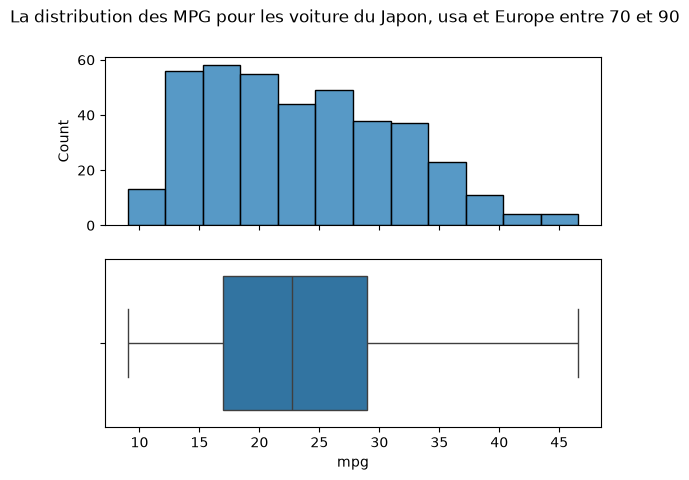

In [6]:
fig, ax = plt.subplots(2,1, sharex=True)
plt.suptitle('La distribution des MPG pour les voiture du Japon, usa et Europe entre 70 et 90')
sns.histplot(df, x="mpg", ax=ax[0])
sns.boxplot(df, x="mpg", ax=ax[1])
plt.show()

### Analyse de la variable cylinders

* Il y'a vraiment beacoup de 4 cylindres parmi les models des années 70-82
* ensuite ce sont les 8 cylindre

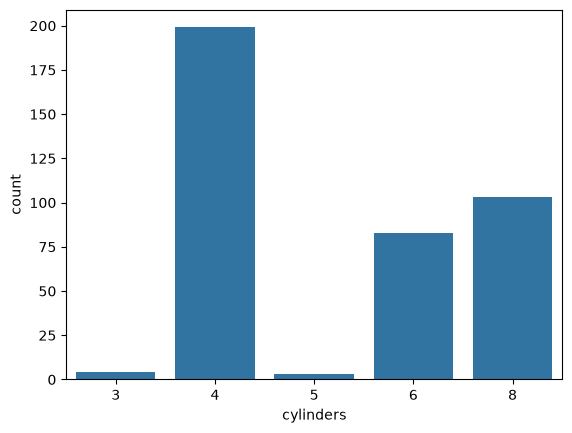

In [7]:
sns.countplot(df, x='cylinders')
plt.show()

### Analyse de la variable origin

* L amjorité des models sont des américaines, et sinon il y'a un nombre equivalent d'européennes et de japonaise dans ce jeu de données


origin
usa       245
japan      79
europe     68
Name: count, dtype: int64


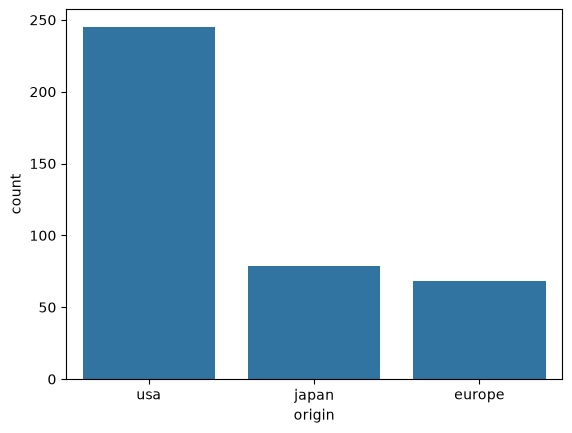

In [8]:
print(df['origin'].value_counts())
sns.countplot(df, x='origin')
plt.show()

### Evolution de la consomation de voiture pas rapport au nombre de chevaux

* On observe que la puissance en cheveau diminue lorsque mpg augmente (c'est-a*dire quand la consomation diminues)
* Cette n'est pas linéaire et suis une tendance quadratique
* On observe qu'a travers le temps, les voitures consomment de moins en moins et on une puissance de plus en plus faible

Test de Pearson
* La  corrélation de pearson est de -0.77
* La probabilité d'observer un resultat non corrélé de ses deux variabale est de 7.031e-81. 

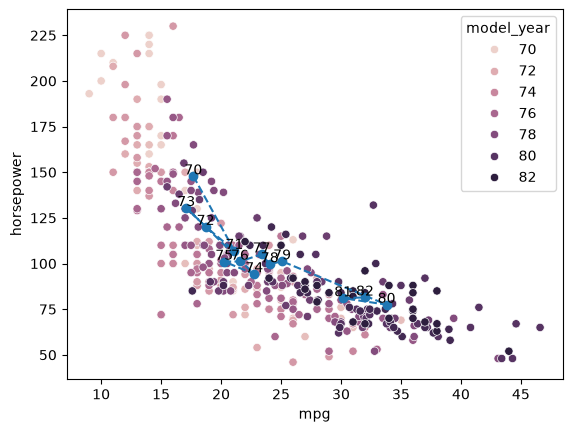

In [9]:
sns.scatterplot(df, x='mpg', y='horsepower', hue='model_year')
temp_df = df.groupby("model_year")[["mpg", 'horsepower' ]].mean()

plt.plot(temp_df['mpg'], temp_df['horsepower'], '--o')
plt.xlabel('mpg')
plt.ylabel('horsepower')

for i, row in temp_df.iterrows():
    plt.text(row['mpg'], row['horsepower'] + 1, i,
             horizontalalignment='center', size='medium', color='black')
plt.show()

In [22]:
stats.pearsonr(df['mpg'], df['horsepower'])


PearsonRResult(statistic=np.float64(-0.7784267838977759), pvalue=np.float64(7.031989029404787e-81))

### Evolution du poid moyens des voiture americaines entre 70 et 8

* Plus les années passe plus les poids moyens des voitures diminue au USA
* Ce n'est pas les cas au japon ou le poids moyen des voiture est le meme et augmente en europe

<Axes: xlabel='model_year', ylabel='weight'>

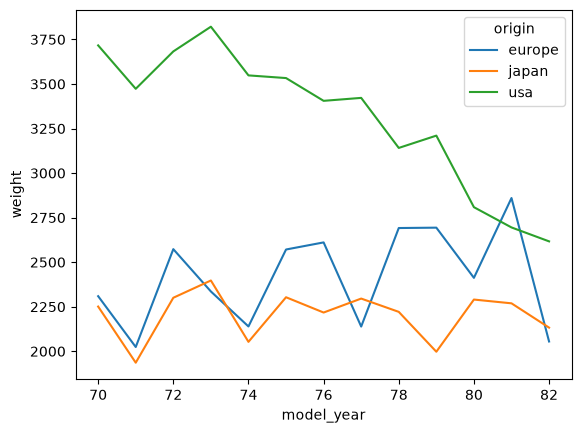

In [10]:
temp_df = df.groupby(['origin', 'model_year'])['weight'].mean().reset_index()
sns.lineplot(temp_df, x='model_year', y='weight' , hue='origin')

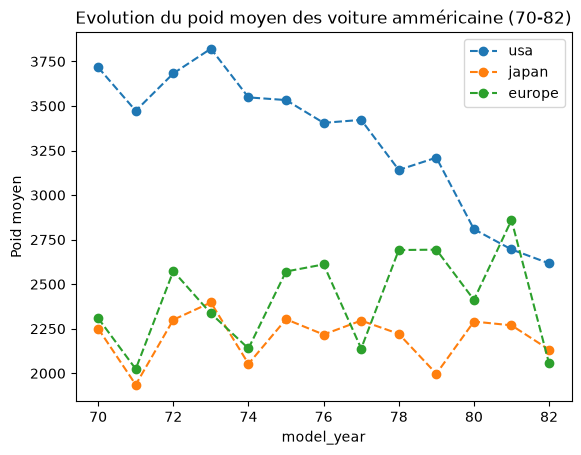

In [11]:
for country in ["usa", "japan", "europe"]:
    temp_df = df.query("origin == @country").groupby('model_year')['weight'].mean()

    plt.plot(temp_df, '--o', label=country)
    plt.title("Evolution du poid moyen des voiture amméricaine (70-82)")
    plt.xlabel('model_year')
    plt.ylabel("Poid moyen")

plt.legend()
plt.show()

### Analyse du nombre de cylindres et l'années du modele

* Il semblerait qu'il y ait de moins en moins de 8  cylindres et de plus en plus de 4 cylindres
* Les moteur à 5 cylindre est est une experience raté des année 78
* seul les moteur avec le nombre de cylyndre pair on suvecu après les année 80

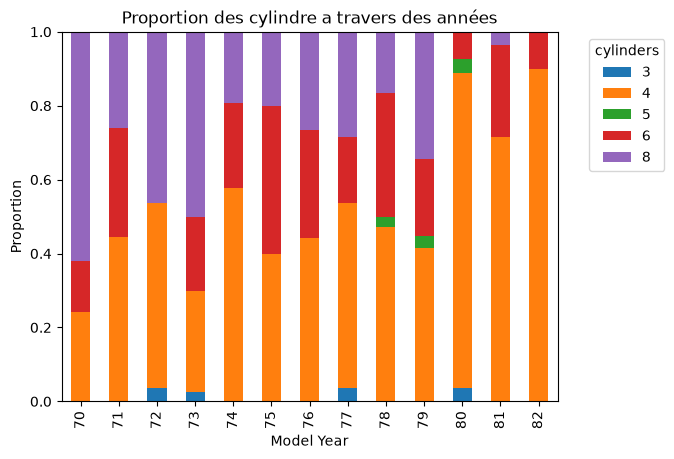

In [12]:
pd.crosstab(df['model_year'],df['cylinders'], normalize='index').plot(kind='bar', stacked=True)
plt.ylabel('Proportion')
plt.xlabel('Model Year')
plt.title('Proportion des cylindre a travers des années')
plt.legend(title='cylinders', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### le nombre de cylindre et origine

* On observe que le nombre de vehicules 4 cylindres est équivalent en europe, au japon et au USA
* Le japon est le seul a avoir les 3 cylindre
*Europe est le seul a avoir les 5 cylindre
* USA sont les seul a avoir les 8 cylindres
* Les USA on beaucoup plus de 6 cylindre que en europe et au japon

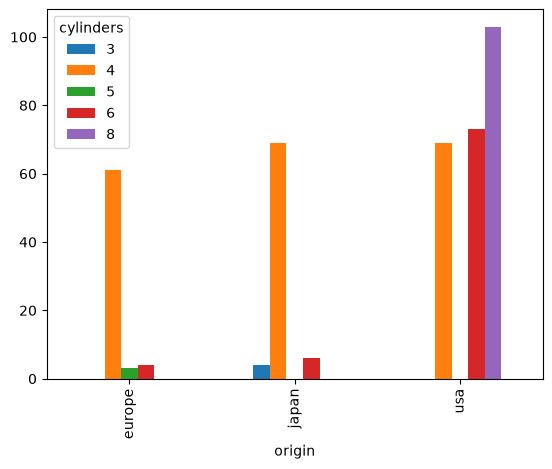

In [13]:
pd.crosstab(df['origin'], df['cylinders']).plot(kind='bar')
plt.show()

### Acceleration moyenne des voiture par pays

* Acceleration moyenne est plus faible au USA que au japon et en europe

In [14]:
df.groupby('origin')['acceleration'].describe()

,count,mean,std,min,25%,50%,75%,max
origin,,,,,,,,
europe,68.0,16.794118,3.087813,12.2,14.5,15.6,19.125,24.8
japan,79.0,16.172152,1.954937,11.4,14.6,16.4,17.550,21.0
usa,245.0,14.990204,2.736020,8.0,13.0,15.0,16.700,22.2


In [15]:
# acceleration pour le smodelle des année 80 est supperieur a ensemble sauf au japon

df.query("model_year == 80").groupby('origin')['acceleration'].describe()

,count,mean,std,min,25%,50%,75%,max
origin,,,,,,,,
europe,8.0,18.500000,3.657868,14.7,15.25,17.85,21.725,23.7
japan,13.0,16.015385,2.402029,11.4,15.00,16.40,17.900,19.2
usa,6.0,17.216667,2.130180,14.4,15.75,17.30,18.550,20.1


### Analyse reste avec le temps

* A travaer le temps autonomie moyenne des voiture augmente (mpg)
    * pour tous les pays: oui
    * pour tous les cylindres? oui
* A travaer le temps accélération moyenne des voitures augmente (mpg)
* A traver le temps le cylindre moyennes des voitures diminue
* A traver le temps le horsepower moyennes des voitures diminue
* A traver le temps le poids moyennes des voitures diminue
    * pour tous les pays: non seulement au USA
    * pour tous les cylindres? non
* A travers le temps, il y'a de plus en plus de véhicule a 4 cylindre et moins en moisn en 8 cylindres

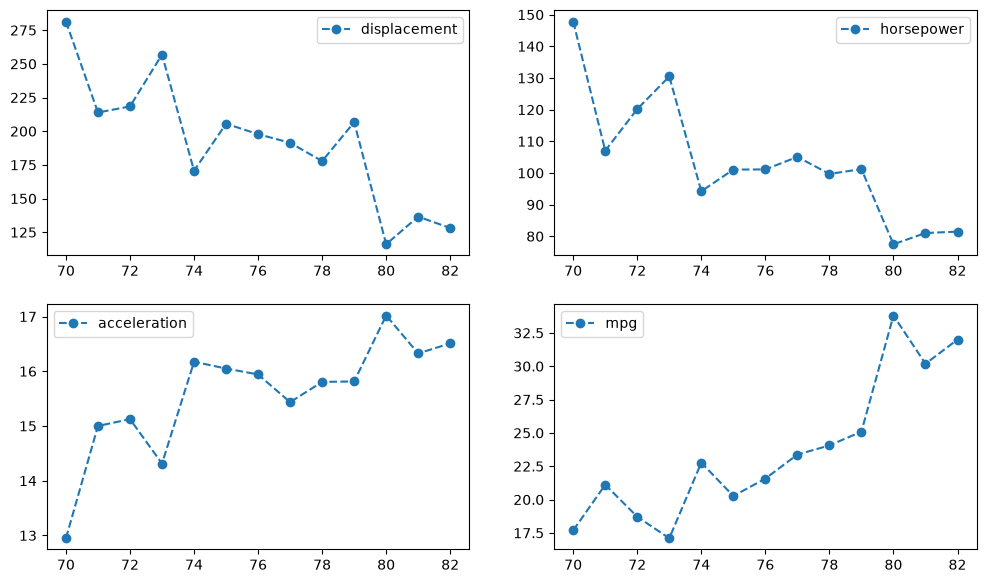

In [16]:
continue_var = ['displacement', 'horsepower', 'acceleration', 'mpg']

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()
for var, axe in zip(continue_var, axes):
    temps_df = df.groupby('model_year')[var].mean()
    axe.plot(temps_df, '--o', label=var)
    axe.legend()

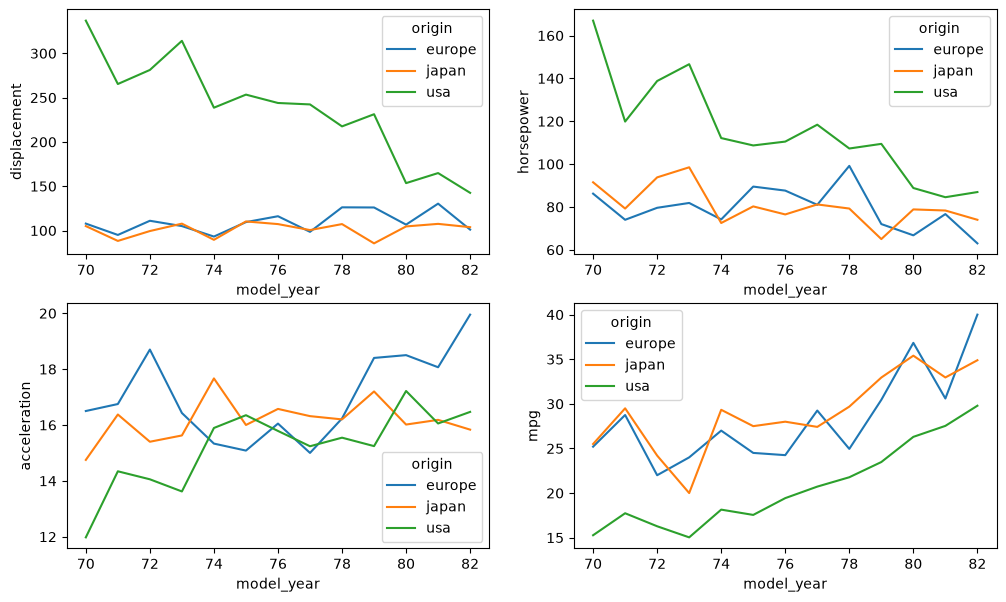

In [17]:
continue_var = ['displacement', 'horsepower', 'acceleration', 'mpg']

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()
for var, axe in zip(continue_var, axes):
    temps_df = df.groupby(['model_year', 'origin'])[var].mean().reset_index()
    sns.lineplot(temps_df, x='model_year', y=var, hue='origin', ax=axe)

### Peut-on affirmer avec un rique d'erreur de 2% que les voitures du japon, d' europe et des Etats - Unis ont vus leur autonomie moyenne augmenter entre la premier moitier des années 70s et al seconde moité des années 70s

* Condition pour utiliser un TTest ind
    * Donnée normal ou plus de 30points
    * Observation indépendantes
    * Variance similaire entre les 2 groupes  ou test de Welh

Hypothèse:
    * H0: "mpg moyen Groupe A = mpg moyen Groupe B"

Conclusion: la p-value est inferieur a alpha: on rejete donc H0
 * La moyenne entre la premiere et la seconde moitier a augmenter et le test de student nous montre ses deux moyenne ne sont pas egales

Moyenne 1 moitier 70s = 19.22 
 Moyenne 2 moitier 70s = 24.470652173913045


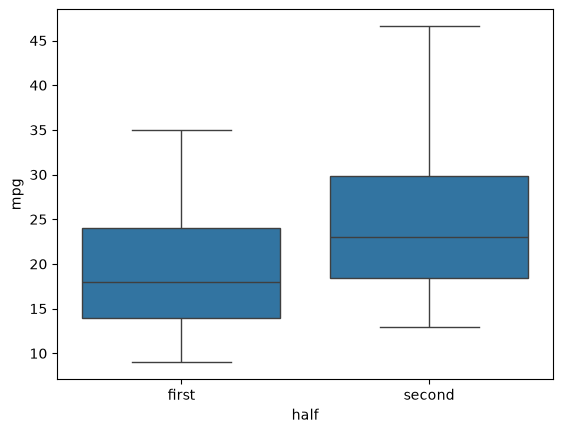

In [ ]:
df_copy = df.copy()
df_copy = df_copy.query("model_year <= 80 ")
df_copy['half'] = df['model_year'].apply(lambda x:  x < 75).replace({True: 'first', False: 'second'})

df_1_70 = df_copy.query("half == 'first'")
df_2_70 = df_copy.query("half == 'second'")

sns.boxplot(df_copy, x='half', y='mpg')
print(f"Moyenne 1 moitier 70s = {df_1_70['mpg'].mean()} \n Moyenne 2 moitier 70s = {df_2_70['mpg'].mean()}")


In [85]:
stats.ttest_ind(df_1_70['mpg'], df_2_70['mpg'], equal_var=False).pvalue
stats.ttest_ind(df_1_70['mpg'], df_2_70['mpg'], equal_var=True).pvalue


np.float64(2.4451466260288248e-11)

###  Un constructeur automobile américain affirme que les voitures américaines à 4 cylindres ont en moyenne la même accélération que les voitures américaines à 6 cylindres. 

Test de student:
    * H0: Les voitures américaines 4 cylindres ont en moyenne la meme accélération que les voitures americaine 6 cylindre
    
Testez cette affirmation et concluez avec un niveau de confiance de 98 % (alpha = 0,02).

In [86]:
df_usa = df.query("origin == 'usa' & model_year <= 80 ")
cylinder_4 = df_usa.query("cylinders == 4")['acceleration']
cylinder_6 = df_usa.query("cylinders == 6")['acceleration']

print(f" Moyenne acceleration 4 cylindre = {cylinder_4.mean()} \n Moyenne acceleration 6 cylindre = {cylinder_6.mean()}")

pvalue = stats.ttest_ind(cylinder_4, cylinder_6).pvalue
if pvalue < 0.02:
    print("Les voitures 4 cylindres et 6 cylindres on une moyennes d'accélération differente")
else:
    print("Les voitures 4 cylindres et 6 cylindres on une meme moyennes d'accélération")


 Moyenne acceleration 4 cylindre = 16.526666666666667 
 Moyenne acceleration 6 cylindre = 16.543939393939397
Les voitures 4 cylindres et 6 cylindres on une meme moyennes d'accélération


### Un collectionneur de voitures vous affirme que parmi les voitures Ford des années 1970-1982, il y avait :

H0: chisquare
    - 25 % de 4 cylindres
    - 25 % de 6 cylindres
    - 50 % de 8 cylindres

Testez son affirmation et concluez avec un niveau de confiance de 95 %.
Conclusion: Nous n'avons pas de preuves suffisament importantes pour rejeter H0 au seuil alpha = 0.05

In [101]:
df_ford = df_usa.query("name.str.contains('ford', case=False, na=False)")
f_obs = df_ford["cylinders"].value_counts().sort_index().values
f_exp = np.array([0.25, 0.25, 0.50]) * f_obs.sum()
pvalue = stats.chisquare(f_obs, f_exp).pvalue
if pvalue < 0.05:
    print("Le collectioneur n'a pas raison sur les proportions")
else:
    print("Nous n'avons pas de preuves suffisament importantes pour rejeter H0 au seuil alpha = 0.05")

Nous n'avons pas de preuves suffisament importantes pour rejeter H0 au seuil alpha = 0.05


### Les voitures à 4 cylindres ont en moyenne la même consommation d'essence au Japon, en Europe et aux États-Unis, dans les années 1970-1982. Testez cette affirmation et concluez avec un niveau de confiance de 98 % (alpha = 0,02).

Conclusion: On doit rejeter l'hypothèse H0: "La consommation moyenne des voitures 4 cylindres est la même au Japon, USA, Europe

In [106]:
df_4cylindre = df.query("cylinders == 4")
print(df_4cylindre.groupby('origin')['mpg'].mean())

mpg_4cylindre = df_4cylindre.groupby('origin')['mpg'].apply(list)
pvalue = stats.f_oneway(*mpg_4cylindre).pvalue
if pvalue < 0.02:
    print("Les voitures 4 cylindres n'ont pas la meme autonomie")
else:
        print("Les voitures 4 cylindres ont la meme autonomie")


origin
europe    28.106557
japan     31.595652
usa       28.013043
Name: mpg, dtype: float64
Les voitures 4 cylindres n'ont pas la meme autonomie


### Les voitures européennes et japonaises ont en moyenne le même nombre de chevaux. Testez cette affirmation et concluez avec un niveau de confiance de 98 % (alpha = 0,02).

H0: Les voitures du japon et de l'europe on en moyenne le meme nombre de chevaux

In [108]:
df_japan = df.query("origin == 'japan' ")
df_europe = df.query("origin == 'europe' ")
japan_horsepower = df_japan['horsepower']
europe_horsepower = df_europe['horsepower']

print(f"Le nombre de chevaux moyens (Japan) = {japan_horsepower.mean()} \nLe nombre de chevaux moyens (Europe) = {europe_horsepower.mean()}")

pvalue = stats.ttest_ind(europe_horsepower, japan_horsepower).pvalue
if pvalue < 0.02:
    print(f"p-value={pvalue}: On peut rejeter l'hypothèse H0 au seuil alpha de 0.02")
else:
    print(f"p-value={pvalue}: On ne peut pas rejeter l'hypothèse H0 au seuil alpha de 0.02")


Le nombre de chevaux moyens (Japan) = 79.83544303797468 
Le nombre de chevaux moyens (Europe) = 80.55882352941177
p-value=0.8176893173506833: On ne peut pas rejeter l'hypothèse H0 au seuil alpha de 0.02


###  Un spécialiste vous dit que les constructeurs Ford et Dodge produisaient dans les années 70-82 des voitures avec un nombre de cylindres équivalent. Testez cette affirmation et concluez avec un niveau de confiance de 98 % (alpha = 0,02).

* Conclusion: Nous n'avons pas suffisament de preuves pour rejeter l'hypothèse H0: 'Le nombre de cylindre est indépendent du constructeur"

In [110]:
df_ford_dodg = df_usa.query("name.str.contains('ford|dodge', case=False, na=False)")
df_ford_dodg["brand"] = df_ford_dodg['name'].apply(lambda x: 'ford' if 'ford' in x else 'dodge')

print(pd.crosstab(df_ford_dodg['brand'], df_ford_dodg['cylinders']))

stats.chi2_contingency(pd.crosstab(df_ford_dodg['brand'], df_ford_dodg['cylinders']))

cylinders   4   6   8
brand                
dodge       8   4  12
ford       11  10  20


Chi2ContingencyResult(statistic=np.float64(0.6429373739226113), pvalue=np.float64(0.7250833342344722), dof=2, expected_freq=array([[ 7.01538462,  5.16923077, 11.81538462],
       [11.98461538,  8.83076923, 20.18461538]]))